节点 3-4 定义完成
节点 5 定义完成
节点 6-7 定义完成


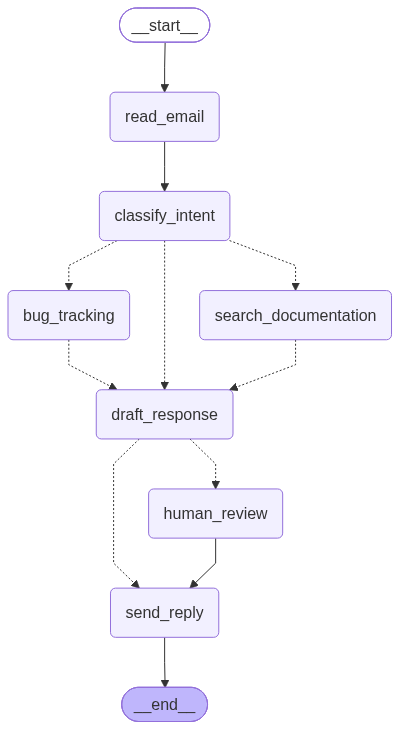

In [1]:
from typing import TypedDict, Literal
from typing import Annotated, TypedDict, Literal, List
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from operator import add
from dotenv import load_dotenv
load_dotenv()
from langchain.chat_models import init_chat_model
# 意图识别的结构化输出
class EmailClassification(TypedDict):
    intent: Literal["question", "bug", "billing", "feature", "complex"]
    urgency: Literal["low", "medium", "high", "critical"]
    topic: str
    summary: str
llm=init_chat_model("deepseek-chat")
# 邮件State
class EmailAgentState(TypedDict):
    # 原始输入
    email_content: str
    sender_email: str
    email_id: str
    # 分类结果
    classification: EmailClassification | None
    # 外部数据
    search_results: list[str] | None
    customer_history: dict | None
    # 生成内容
    draft_response: str | None
from typing import Literal
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command, RetryPolicy

# 给LLM绑定结构化输出，做为路由决策
classifier_llm = llm.with_structured_output(EmailClassification)

def read_email(state: EmailAgentState) -> dict:
    """节点1: 解析邮件——总是走到下一个固定节点"""
    # 真实业务可以连接邮件服务器，读取信息
    print(f"  [Read] 收到邮件: {state['email_id']}")
    return {}

# 这里基于Command直接编写跳转规则，省去了conditional edge
def classify_intent(state: EmailAgentState)-> Command[Literal["search_documentation", "bug_tracking", "draft_response"]]:
    """节点2: LLM分类 + 路由决策"""
    # 先调用llm，做意图识别分类
    classification = classifier_llm.invoke(f"""
        分析这封客户邮件并分类：
        邮件: {state['email_content']}
        发件人: {state['sender_email']}
        提供 intent（question/bug/billing/feature/complex）、urgency、topic、summary。
    """)

    # 根据分类结果决定数据 下个Node
    if classification['intent'] in ['question', 'feature']:
        goto = "search_documentation"
    elif classification['intent'] == 'bug':
        goto = "bug_tracking"
    else:
        # billing、complex → 跳过数据收集，直接生成草稿（draft 会判断是否需要人工审核）
        goto = "draft_response"

    print(f"  [Classify] intent={classification['intent']}, urgency={classification['urgency']}")
    print(f"  [Classify] -> 路由到: {goto}")
    return Command(
        update={"classification": classification},
        goto=goto
    )
# 文档搜索/BUG工单处理完成后直接跳去draft_response，直接用Command跳转

def search_documentation(state: EmailAgentState) ->Command[Literal['draft_response']]:
    """节点3: 搜索知识库（带重试策略）"""
    classification = state.get('classification', {})
    query = f"{classification.get('intent', '')} {classification.get('topic', '')}"
    print(f"  [Search] 查询: {query}")

    # 模拟知识库搜索，实际开发可以改为RAG
    search_results = [
        "密码重置: 登录 -> 设置 -> 安全 -> 修改密码",
        "密码至少12位，包含大小写和特殊字符",
        "两步验证开启方法: 安全设置 -> 两步验证"
    ]
    return Command(
        update={"search_results": search_results},
        goto="draft_response"
    )

def bug_tracking(state: EmailAgentState) ->Command[Literal['draft_response']]:
    """节点4: 创建 Bug 工单"""
    ticket_id = f"BUG-{hash(state['email_id']) % 100000:05d}"
    print(f"  [BugTrack] 创建工单 {ticket_id}")

    return Command(
        update={
            "search_results": [f"Bug 工单 {ticket_id} 已创建"],
            "customer_history": {"ticket_id": ticket_id}
        },
        goto="draft_response"
    )

print("节点 3-4 定义完成")
def draft_response(state: EmailAgentState) -> Command[Literal["human_review", "send_reply"]]:
    """节点5: LLM生成回复草稿 + 判断是否需要人工审核"""
    classification = state.get('classification', {})

    # 格式化上下文（在节点内部格式化，不污染State）
    context_parts = []
    if state.get('search_results'):
        context_parts.append("文档:\n" + "\n".join(f"- {r}" for r in state['search_results']))
    if state.get('customer_history'):
        context_parts.append(f"工单: {state['customer_history']}")

    prompt = f"""起草一封回复邮件：
客户: {state['sender_email']}
原邮件: {state['email_content']}
意图: {classification.get('intent')} | 紧急度: {classification.get('urgency')}
{chr(10).join(context_parts)}

要求：专业、友好、有针对性地解决用户问题。不超过100字。落款统一写“黑马程序员”。"""

    response = llm.invoke(prompt)
    print(f"  [Draft] 回复已生成 ({len(response.content)} 字符)")

    # 判断是否需要人工审核，对于紧急任务、复杂任务、账单相关，都走人工审核
    needs_review = (
        classification.get('urgency') in ['high', 'critical'] or
        classification.get('intent') in ['complex', 'billing']
    )
    goto = "human_review" if needs_review else "send_reply"
    print(f"  [Draft] -> 路由到: {goto}")

    return Command(update={"draft_response": response.content}, goto=goto)

print("节点 5 定义完成")
from langgraph.types import interrupt  # interrupt 在 langgraph.types 中

def human_review(state: EmailAgentState):
    """节点6: 人工审核"""
    classification = state.get('classification', {})

    human_decision = interrupt({
        "email_id": state.get('email_id',''),
        "original_email": state.get('email_content',''),
        "draft_response": state.get('draft_response',''),
        "urgency": classification.get('urgency'),
        "intent": classification.get('intent'),
        "action": "请审阅并批准或编辑此回复,输入[approve 或 edit]"
    })

    # Now process the human's decision
    if human_decision.get("action") == 'edit':
        # edit，用户修改了邮件，需要更新State
        return {"draft_response": human_decision.get("edited_response")}
    else:
        # approve，没有修改邮件，直接发送
        return {}

def send_reply(state: EmailAgentState) -> dict:
    """节点7: 发送邮件回复"""
    draft = state.get('draft_response', '')
    print(f"  [Send] 发送回复邮件给{state['sender_email']}成功...\n\n{draft}")
    return {}

print("节点 6-7 定义完成")
from langgraph.checkpoint.memory import InMemorySaver

workflow = StateGraph(EmailAgentState)

# 添加所有节点
workflow.add_node("read_email", read_email)
workflow.add_node("classify_intent", classify_intent)
# 带重试策略的节点
workflow.add_node(
    "search_documentation",
    search_documentation,
    retry_policy=RetryPolicy(max_attempts=3, initial_interval=1.0)
)
workflow.add_node("bug_tracking", bug_tracking)
workflow.add_node("draft_response", draft_response)
workflow.add_node("human_review", human_review)
workflow.add_node("send_reply", send_reply)

# 定义最小边，大部分跳转都已通过Command实现，只用定义少量串行edge即可
workflow.add_edge(START, "read_email")
workflow.add_edge("read_email", "classify_intent")
workflow.add_edge("human_review", "send_reply")
workflow.add_edge("send_reply", END)

# compile 时需要 checkpointer（interrupt 需要持久化）
app = workflow.compile(checkpointer=InMemorySaver())
def display_graph(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))
display_graph(app)

In [2]:
# 测试三个不同场景
config_base = {"configurable": {"thread_id": "test"}}

print("=== 场景1: 密码重置（查文档 → 自动回复）===\n")
config1 = {"configurable": {"thread_id": "t1"}}
r1 = app.invoke({
    "email_content": "Hi，我忘记登录密码了，如何重置？",
    "sender_email": "jack@example.com", "email_id": "email-001",
    "classification": None, "search_results": None,
    "customer_history": None, "draft_response": None
}, config1)

=== 场景1: 密码重置（查文档 → 自动回复）===

  [Read] 收到邮件: email-001
  [Classify] intent=question, urgency=medium
  [Classify] -> 路由到: search_documentation
  [Search] 查询: question 密码重置 / 账号登录
  [Draft] 回复已生成 (145 字符)
  [Draft] -> 路由到: send_reply
  [Send] 发送回复邮件给jack@example.com成功...

**主题：回复：如何重置登录密码**

Hi Jack，

忘记密码很常见，别担心。请按以下步骤重置：登录页面 → 设置 → 安全 → 修改密码。

新密码需至少12位，包含大小写字母和特殊字符。建议同时开启两步验证：安全设置 → 两步验证。

如需协助，请随时回复。

祝好，
黑马程序员


In [3]:
print(f"\n=== 场景2: Bug报告（建工单 → 回复）===\n")
config2 = {"configurable": {"thread_id": "t2"}}
r2 = app.invoke({
    "email_content": "PDF导出功能每次都会崩溃，急需修复！",
    "sender_email": "jane@corp.com", "email_id": "email-002",
    "classification": None, "search_results": None,
    "customer_history": None, "draft_response": None, "messages": None
}, config2)

print(f"  回复: {r2['draft_response']}...")


=== 场景2: Bug报告（建工单 → 回复）===

  [Read] 收到邮件: email-002
  [Classify] intent=bug, urgency=critical
  [Classify] -> 路由到: bug_tracking
  [BugTrack] 创建工单 BUG-41109
  [Draft] 回复已生成 (114 字符)
  [Draft] -> 路由到: human_review
  回复: 主题：回复：PDF导出功能崩溃问题

尊敬的Jane：

您好！非常抱歉给您带来不便。我们已为您创建紧急工单BUG-41109，技术团队正在优先处理PDF导出崩溃问题，将尽快修复并同步进展。

感谢您的耐心与支持！

黑马程序员...


In [4]:

print(f"\n=== 场景3: 账单问题（直接升级人工审核）===\n")
config3 = {"configurable": {"thread_id": "t3"}}
r3 = app.invoke({
    "email_content": "我被重复扣款了！这是什么情况！请立刻处理！",
    "sender_email": "jack@corp.com", "email_id": "vip-email-003",
    "classification": None, "search_results": None,
    "customer_history": None, "draft_response": None, "messages": None
}, config3)


=== 场景3: 账单问题（直接升级人工审核）===

  [Read] 收到邮件: vip-email-003
  [Classify] intent=billing, urgency=critical
  [Classify] -> 路由到: draft_response
  [Draft] 回复已生成 (90 字符)
  [Draft] -> 路由到: human_review


In [5]:
# 人工确认，比如approve
r4 = app.invoke(
    Command(resume={
        "action": "edit",
        "edited_response": """
    尊敬的VIP客户jack，

    非常抱歉给您带来不便！我们已紧急核查您的账户，确认存在重复扣款。我们将立即为您办理退款，预计1小时内原路返回。如有其他问题，请随时联系我们。再次感谢您的耐心！

    黑马程序员
        """
    }),
    config3
)

  [Send] 发送回复邮件给jack@corp.com成功...


    尊敬的VIP客户jack，

    非常抱歉给您带来不便！我们已紧急核查您的账户，确认存在重复扣款。我们将立即为您办理退款，预计1小时内原路返回。如有其他问题，请随时联系我们。再次感谢您的耐心！

    黑马程序员
        
